# From probabilistic to deflated Sharpe ratios

A sample Sharpe ratio compares the average return with the observed return variation:

$$
\widehat{SR}=\frac{\overline r}{s_r},
\qquad
\overline r=\frac{1}{T}\sum_{t=1}^{T}r_t,
\qquad
s_r^2=\frac{1}{T-1}\sum_{t=1}^{T}(r_t-\overline r)^2.
$$

Here, $r_t$ is the return at observation $t$, $T$ is the number of returns, $\overline r$ is their sample mean, $s_r$ is their sample standard deviation, and $\widehat{SR}$ is the per-period sample Sharpe ratio when the comparison return is zero.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import math
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
from RiskLabAI.backtest.probabilistic_sharpe_ratio import benchmark_sharpe_ratio, probabilistic_sharpe_ratio
from RiskLabAI.backtest.sharpe_inference import lplz_sharpe_inference, newey_west_automatic_lag, newey_west_long_run_variance, sharpe_ratio_influence_function
from RiskLabAI.backtest.multiple_testing import benjamini_hochberg_yekutieli_adjusted_p_values, haircut_sharpe_ratios, holm_adjusted_p_values, sharpe_ratio_p_values
from RiskLabAI.backtest.test_set_overfitting import expected_max_sharpe_ratio, estimated_sharpe_ratio_z_statistics, strategy_type1_error_probability, strategy_type2_error_probability, theta_for_type2_error
from RiskLabAI.backtest.robust_statistics import sharpe_difference_test
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_sp500')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH)
raw['observation_date'] = pd.to_datetime(raw['observation_date'])
prices = raw.set_index('observation_date')['SP500'].dropna().astype(float).sort_index()
log_returns = np.log(prices).diff()
fast_windows = [3, 5, 10, 20]
slow_windows = [30, 60, 120, 240]
performance_columns = {}
catalog_rows = []
for fast_window in fast_windows:
    for slow_window in slow_windows:
        fast_average = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow_average = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
        trend_position = np.sign(fast_average - slow_average).replace(0, np.nan).ffill().shift(1)
        for orientation, multiplier in [('Trend', 1.0), ('Reversal', -1.0)]:
            name = f'{orientation} {fast_window}/{slow_window}'
            performance_columns[name] = multiplier * trend_position * log_returns
            catalog_rows.append({'Trial': len(catalog_rows) + 1, 'Rule': orientation, 'Fast span': fast_window, 'Slow span': slow_window, 'Name': name})
performances = pd.DataFrame(performance_columns).dropna()
strategy_catalog = pd.DataFrame(catalog_rows)
FIGURES = ROOT / 'outputs' / 'figures' / '20_sharpe_multiple_testing'
TABLES = ROOT / 'outputs' / 'tables' / '20_sharpe_multiple_testing'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('-inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def period_sharpe(values):
    array = np.asarray(values, dtype=float)
    deviation = array.std(ddof=1)
    return float(array.mean() / deviation) if deviation > 0 else 0.0

def return_moments(values):
    array = np.asarray(values, dtype=float)
    return (float(ss.skew(array, bias=False)), float(ss.kurtosis(array, fisher=False, bias=False)))

def opposite_name(name):
    return name.replace('Trend', 'Reversal') if name.startswith('Trend') else name.replace('Reversal', 'Trend')
trial_sharpes = np.array([period_sharpe(performances[column]) for column in performances])
annual_sharpes = trial_sharpes * np.sqrt(252.0)
trial_mean = float(trial_sharpes.mean())
trial_spread = float(trial_sharpes.std(ddof=0))
trial_count = performances.shape[1]
observation_count = performances.shape[0]
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Trial Family

,Field,Value
0,Series,S&P 500
1,Provider,Federal Reserve Bank of St. Louis
2,Source,https://fred.stlouisfed.org/graph/fredgraph.cs...
3,Retrieved,2026-09-28
4,First price,2016-09-26
5,Last price,2025-12-31
6,Price observations,"2,330"
7,Trial observations,"2,090"
8,Trials,32


,Trial,Name,Annual Sharpe,Skewness,Kurtosis,PSR against zero,Expected maximum benchmark,Deflated probability
0,1,Trend 3/30,0.368432,0.187386,18.211399,0.855851,0.589005,0.262481
1,2,Reversal 3/30,-0.368432,-0.187386,18.211399,0.144149,0.589005,0.002895
2,3,Trend 3/60,0.252547,0.125187,18.212152,0.766527,0.589005,0.166232
3,4,Reversal 3/60,-0.252547,-0.125187,18.212152,0.233473,0.589005,0.007674
4,5,Trend 3/120,0.290021,0.045606,18.219250,0.798077,0.589005,0.194738
5,6,Reversal 3/120,-0.290021,-0.045606,18.219250,0.201923,0.589005,0.005701
6,7,Trend 3/240,0.199220,-0.050282,18.219752,0.716751,0.589005,0.131032
7,8,Reversal 3/240,-0.199220,0.050282,18.219752,0.283249,0.589005,0.011666
8,9,Trend 5/30,0.448622,0.276929,18.205382,0.902255,0.589005,0.342710
9,10,Reversal 5/30,-0.448622,-0.276929,18.205382,0.097745,0.589005,0.001376


,Trial,Name,Annual Sharpe,Skewness,Kurtosis,PSR against zero,Expected maximum benchmark,Deflated probability
8,9,Trend 5/30,0.448622,0.276929,18.205382,0.902255,0.589005,0.342710
26,27,Trend 20/60,0.413375,0.111026,18.221488,0.883009,0.589005,0.306547
12,13,Trend 5/120,0.370794,0.048425,18.224506,0.856999,0.589005,0.265039
0,1,Trend 3/30,0.368432,0.187386,18.211399,0.855851,0.589005,0.262481
20,21,Trend 10/120,0.356375,0.098711,18.218891,0.847576,0.589005,0.251493
16,17,Trend 10/30,0.342441,0.261665,18.203974,0.838362,0.589005,0.238480
4,5,Trend 3/120,0.290021,0.045606,18.219250,0.798077,0.589005,0.194738
2,3,Trend 3/60,0.252547,0.125187,18.212152,0.766527,0.589005,0.166232
14,15,Trend 5/240,0.250915,0.020998,18.218704,0.764902,0.589005,0.165262
18,19,Trend 10/60,0.216851,0.079692,18.213746,0.733831,0.589005,0.141938


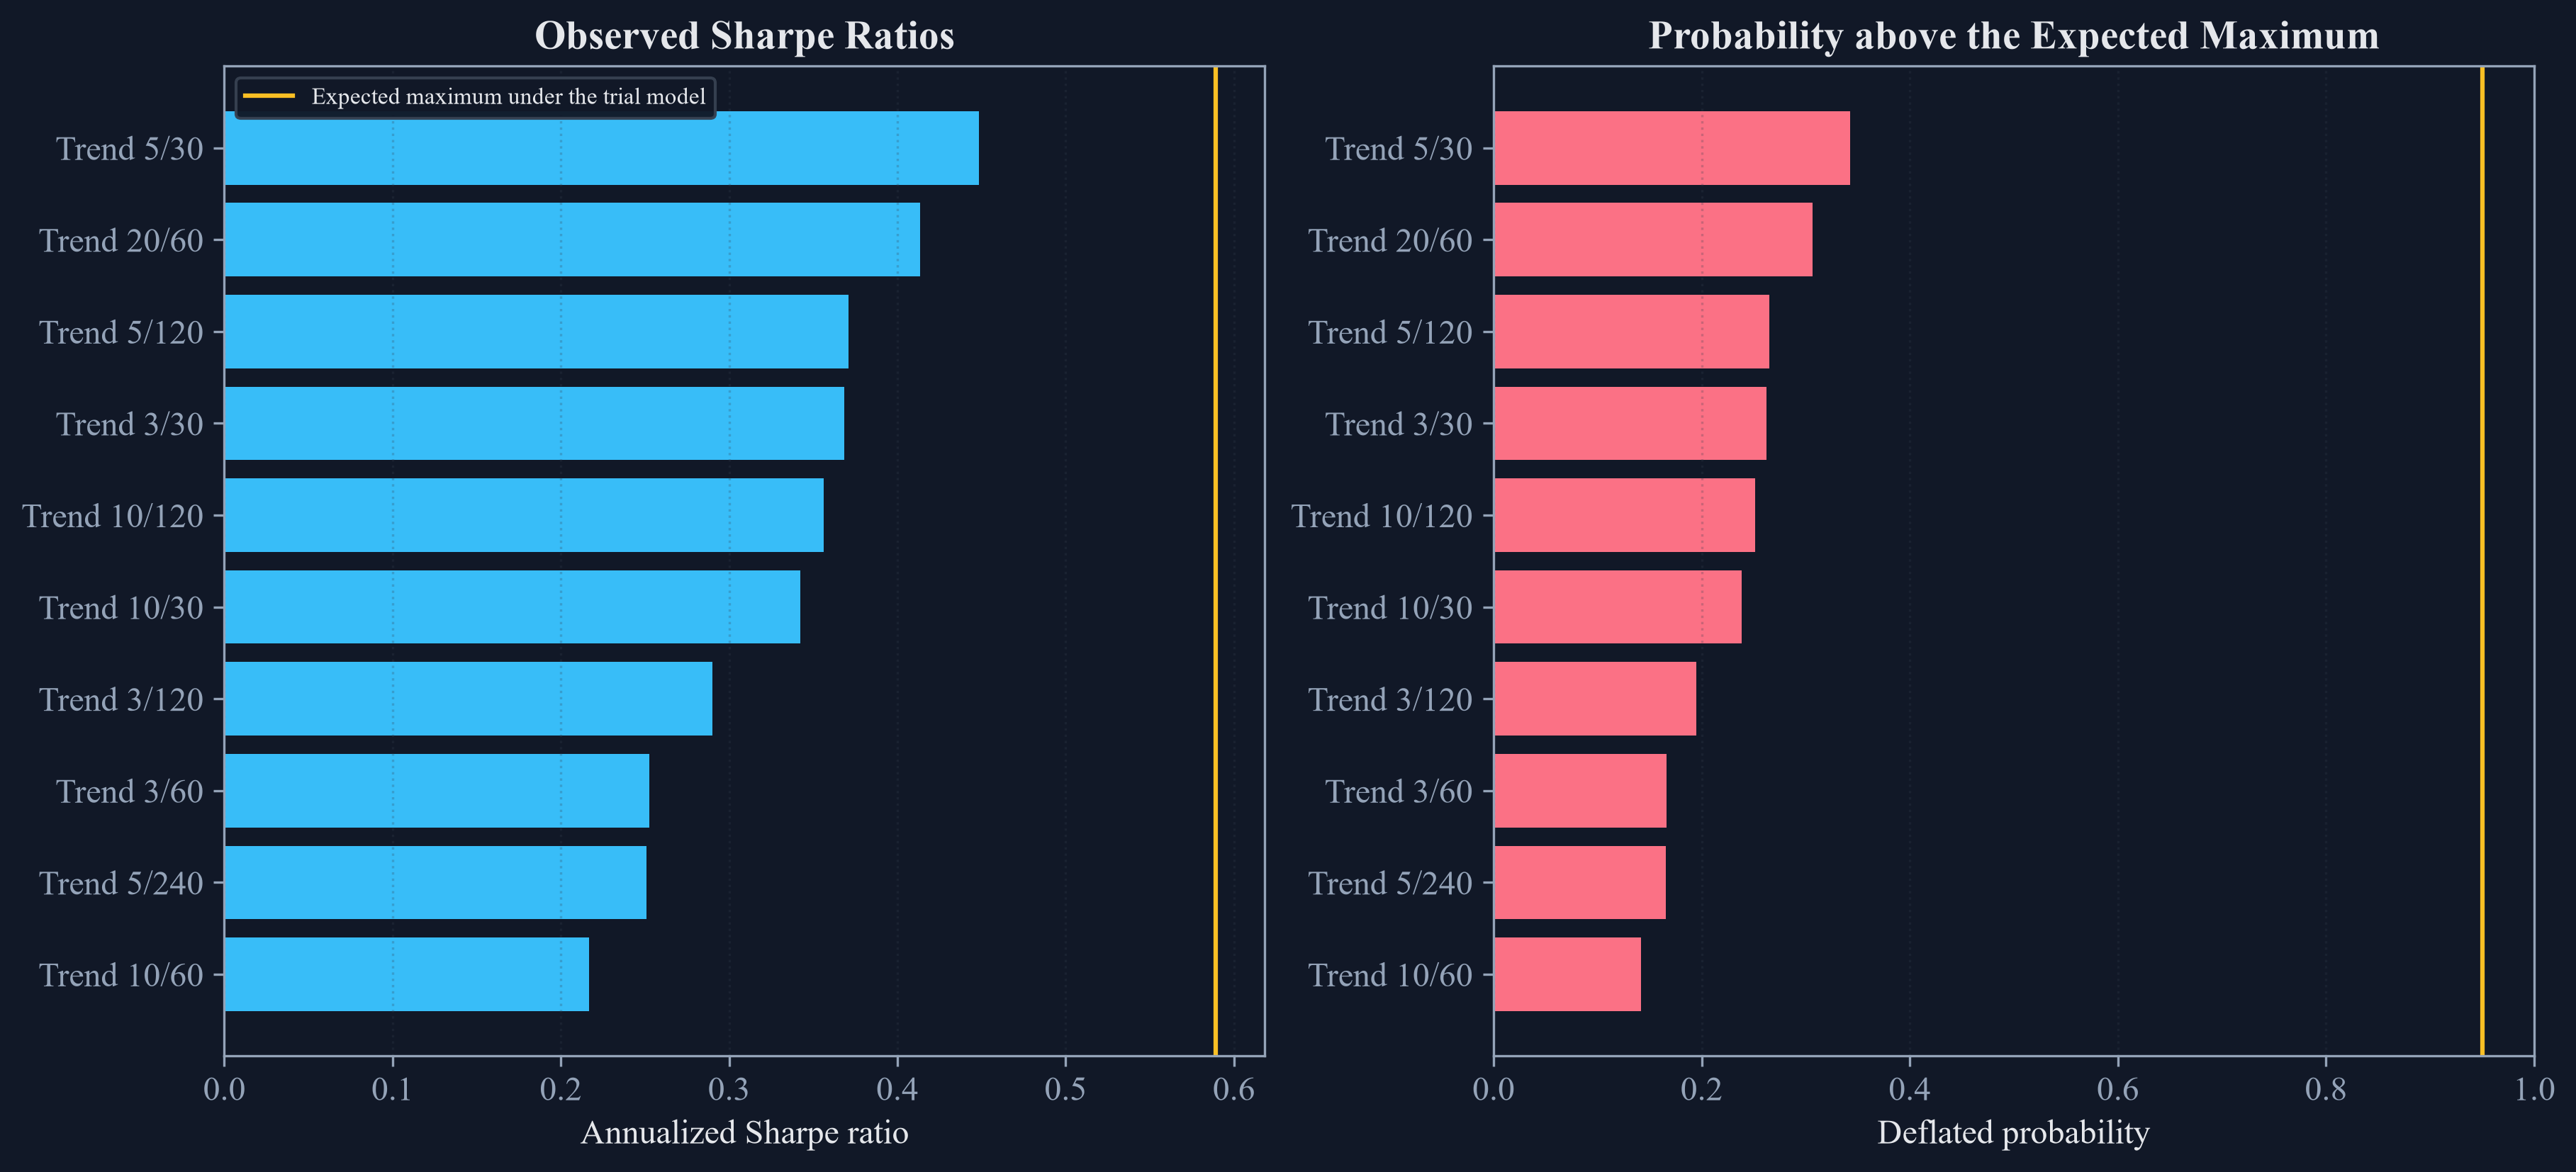

In [2]:
data_provenance = pd.DataFrame({'Field': ['Series', 'Provider', 'Source', 'Retrieved', 'First price', 'Last price', 'Price observations', 'Trial observations', 'Trials'], 'Value': ['S&P 500', 'Federal Reserve Bank of St. Louis', DATA_URL, '2026-09-28', str(prices.index.min().date()), str(prices.index.max().date()), f'{len(prices):,}', f'{observation_count:,}', trial_count]})
expected_maximum = expected_max_sharpe_ratio(trial_count, trial_mean, trial_spread)
inference_rows = []
for trial_number, name in enumerate(performances.columns, start=1):
    values = performances[name].to_numpy()
    sharpe = period_sharpe(values)
    skewness, kurtosis = return_moments(values)
    psr_zero = probabilistic_sharpe_ratio(sharpe, 0.0, len(values), skewness, kurtosis)
    deflated_probability = probabilistic_sharpe_ratio(sharpe, expected_maximum, len(values), skewness, kurtosis)
    inference_rows.append({'Trial': trial_number, 'Name': name, 'Annual Sharpe': sharpe * np.sqrt(252.0), 'Skewness': skewness, 'Kurtosis': kurtosis, 'PSR against zero': psr_zero, 'Expected maximum benchmark': expected_maximum * np.sqrt(252.0), 'Deflated probability': deflated_probability})
public_sharpe_inference = pd.DataFrame(inference_rows)
leading_public_inference = public_sharpe_inference.sort_values(['Annual Sharpe', 'Trial'], ascending=[False, True]).head(10)
save_table(data_provenance, 'data_provenance', 'Public observations used in Chapter 18.', 'tab:chapter18-data-provenance')
save_table(public_sharpe_inference, 'public_sharpe_inference', 'Sharpe inference for every public trial.', 'tab:chapter18-public-sharpe-all')
save_table(leading_public_inference, 'leading_public_inference', 'The ten largest full-sample Sharpe ratios and their probability adjustments.', 'tab:chapter18-leading-sharpe')
display(data_provenance)
display(public_sharpe_inference)
display(leading_public_inference)
leading = leading_public_inference.sort_values('Annual Sharpe')
figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.4), constrained_layout=True)
axes[0].barh(leading['Name'], leading['Annual Sharpe'], color=palette['cyan'])
axes[0].axvline(expected_maximum * np.sqrt(252.0), color=palette['amber'], linewidth=1.5, label='Expected maximum under the trial model')
axes[0].set_title('Observed Sharpe Ratios')
axes[0].set_xlabel('Annualized Sharpe ratio')
axes[0].legend(fontsize=8)
axes[0].grid(axis='x', alpha=0.25)
axes[1].barh(leading['Name'], leading['Deflated probability'], color=np.where(leading['Deflated probability'] >= 0.95, palette['green'], palette['rose']))
axes[1].axvline(0.95, color=palette['amber'], linewidth=1.5)
axes[1].set_xlim(0, 1)
axes[1].set_title('Probability above the Expected Maximum')
axes[1].set_xlabel('Deflated probability')
axes[1].grid(axis='x', alpha=0.25)
figure.savefig(FIGURES / 'public_deflated_sharpe.png', bbox_inches='tight', dpi=300)
figure.savefig(FIGURES / 'public_deflated_sharpe.pdf', bbox_inches='tight')
display(Image(filename=str(FIGURES / 'public_deflated_sharpe.png')))
plt.close(figure)


A multiple-trial benchmark approximates the expected largest Sharpe ratio in a family of independent normal estimates:

$$
SR^*_{N}
=\mu_{SR}+\sigma_{SR}\left[(1-\gamma)\Phi^{-1}\!\left(1-\frac{1}{N}\right)+\gamma\Phi^{-1}\!\left(1-\frac{1}{Ne}\right)\right].
$$

Here, $SR^*_{N}$ is the expected maximum among $N$ trials, $\mu_{SR}$ and $\sigma_{SR}$ are the mean and standard deviation of the trial Sharpe estimates, $\gamma$ is the Euler-Mascheroni constant, $\Phi^{-1}$ is the standard-normal quantile function, and $e$ is Euler's number.

## Expected Maximum under Repeated Trials

,Trials,Benchmark from public spread,Benchmark when mean is zero
0,1,0,0
1,5,0.334518,0.334518
2,10,0.441669,0.441669
3,20,0.533141,0.533141
4,32,0.589005,0.589005
5,50,0.638494,0.638494
6,100,0.709824,0.709824


,Trials,Simulations,Analytical expected maximum,Simulated mean maximum,Simulated standard error
0,1,5000,0,-0.002713,0.006942
1,5,5000,0.596297,0.582983,0.004782
2,20,5000,0.950354,0.934360,0.003754
3,100,5000,1.265301,1.253755,0.003015


,Quantity,Value
0,Strategies,100
1,Simulations,1000
2,Sharpe mean,0
3,Sharpe spread,0.500000
4,Analytical expected maximum,1.265301
5,Simulated mean maximum,1.254806
6,Simulated standard error,0.006707


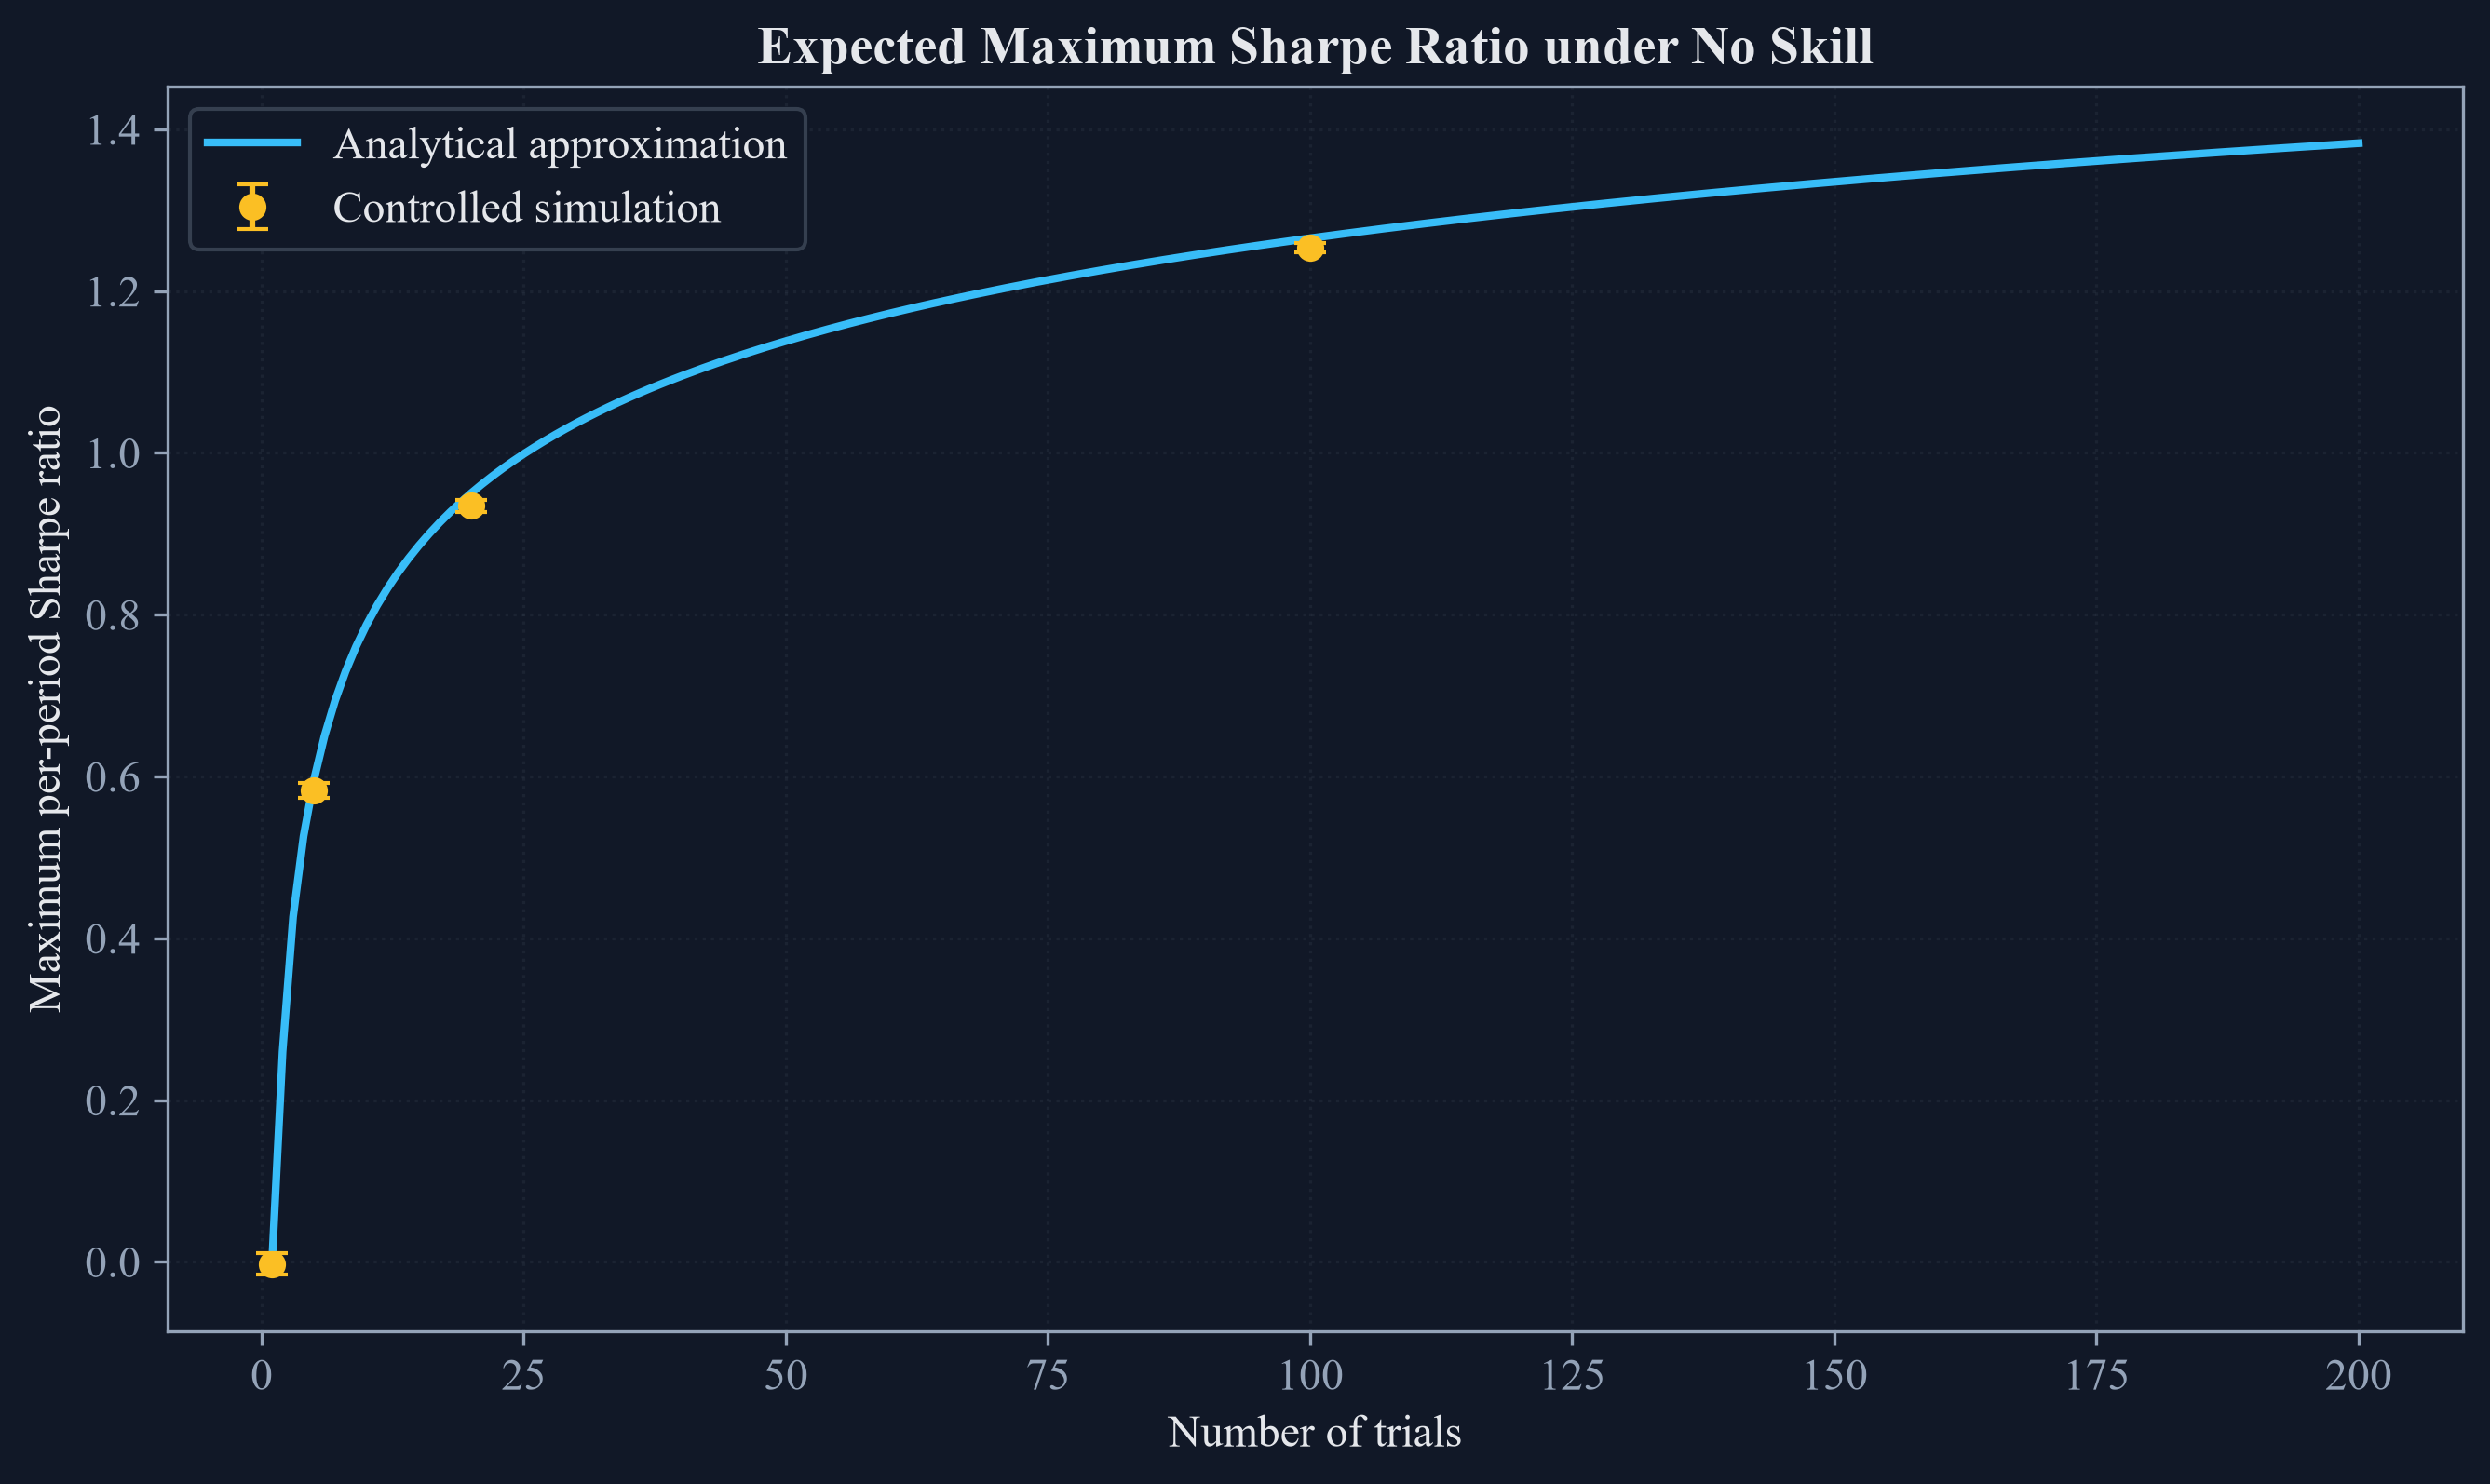

In [3]:
trial_counts = [1, 5, 10, 20, 32, 50, 100]
expected_maximum_sensitivity = pd.DataFrame({
    "Trials": trial_counts,
    "Benchmark from public spread": [expected_max_sharpe_ratio(count, trial_mean, trial_spread) * np.sqrt(252.0) for count in trial_counts],
    "Benchmark when mean is zero": [expected_max_sharpe_ratio(count, 0.0, trial_spread) * np.sqrt(252.0) for count in trial_counts],
})
rng = np.random.default_rng(20260928)
simulation_rows = []
simulation_scale = 0.5
for count in [1, 5, 20, 100]:
    simulated = rng.normal(0.0, simulation_scale, size=(5000, count))
    maxima = simulated.max(axis=1)
    simulation_rows.append({"Trials": count, "Simulations": len(maxima), "Analytical expected maximum": expected_max_sharpe_ratio(count, 0.0, simulation_scale), "Simulated mean maximum": maxima.mean(), "Simulated standard error": maxima.std(ddof=1) / np.sqrt(len(maxima))})
expected_maximum_simulation = pd.DataFrame(simulation_rows)
preliminary_rng = np.random.default_rng(20260928)
preliminary_maxima = preliminary_rng.normal(0.0, 0.5, size=(1000, 100)).max(axis=1)
preliminary_expected_max_reproduction = pd.DataFrame({
    "Quantity": ["Strategies", "Simulations", "Sharpe mean", "Sharpe spread", "Analytical expected maximum", "Simulated mean maximum", "Simulated standard error"],
    "Value": [100, 1000, 0.0, 0.5, expected_max_sharpe_ratio(100, 0.0, 0.5), preliminary_maxima.mean(), preliminary_maxima.std(ddof=1) / np.sqrt(1000)],
})
save_table(expected_maximum_sensitivity, "expected_maximum_sensitivity", "Expected maximum Sharpe ratios as the number of trials changes.", "tab:chapter18-expected-maximum-sensitivity")
save_table(expected_maximum_simulation, "expected_maximum_simulation", "Analytical and simulated maximum Sharpe ratios under a known null.", "tab:chapter18-expected-maximum-simulation")
save_table(preliminary_expected_max_reproduction, "preliminary_expected_max_reproduction", "Controlled reproduction of the preliminary one-hundred-strategy experiment.", "tab:chapter18-preliminary-maximum", fit=False)
display(expected_maximum_sensitivity)
display(expected_maximum_simulation)
display(preliminary_expected_max_reproduction)

count_grid = np.arange(1, 201)
analytic_curve = np.array([expected_max_sharpe_ratio(int(count), 0.0, simulation_scale) for count in count_grid])
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
axis.plot(count_grid, analytic_curve, color=palette["cyan"], linewidth=2.0, label="Analytical approximation")
axis.errorbar(expected_maximum_simulation["Trials"], expected_maximum_simulation["Simulated mean maximum"], yerr=1.96 * expected_maximum_simulation["Simulated standard error"], fmt="o", color=palette["amber"], capsize=4, label="Controlled simulation")
axis.set_title("Expected Maximum Sharpe Ratio under No Skill")
axis.set_xlabel("Number of trials")
axis.set_ylabel("Maximum per-period Sharpe ratio")
axis.legend()
axis.grid(alpha=0.28)
figure.savefig(FIGURES / "expected_maximum_curve.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "expected_maximum_curve.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "expected_maximum_curve.png")))
plt.close(figure)

The probabilistic Sharpe calculation places an observed Sharpe ratio in a reference probability distribution:

$$
Z=\frac{(\widehat{SR}-SR^*)\sqrt{T-1}}{\sqrt{1-\widehat\gamma_3\widehat{SR}+\frac{\widehat\gamma_4-1}{4}\widehat{SR}^{,2}}},
\qquad
\operatorname{PSR}=\Phi(Z).
$$

Here, $\widehat{SR}$ is the observed per-period Sharpe ratio, $SR^*$ is the chosen benchmark, $T$ is the number of returns, $\widehat\gamma_3$ is sample skewness, $\widehat\gamma_4$ is ordinary kurtosis, $Z$ is the standardized distance from the benchmark, and $\Phi$ is the standard-normal distribution function.

## How sample length and return shape affect Sharpe inference

,Returns,Observed Sharpe,Normal returns,Negative skew and thick tails
0,60,0.02,0.561040,0.560737
1,60,0.05,0.649443,0.647655
2,60,0.10,0.778222,0.772450
3,60,0.15,0.874050,0.864907
4,60,0.20,0.935882,0.925794
5,120,0.02,0.586345,0.585919
6,120,0.05,0.707156,0.704798
7,120,0.10,0.861736,0.855609
8,120,0.15,0.948151,0.941320
9,120,0.20,0.984623,0.979935


,Calculation,Sharpe used in formula,Returns,Skewness,Kurtosis,PSR against zero
0,Preliminary numerical input,1.980000,2520,-0.5,4,1
1,Daily value consistent with annual Sharpe,0.124728,2520,-0.5,4,1


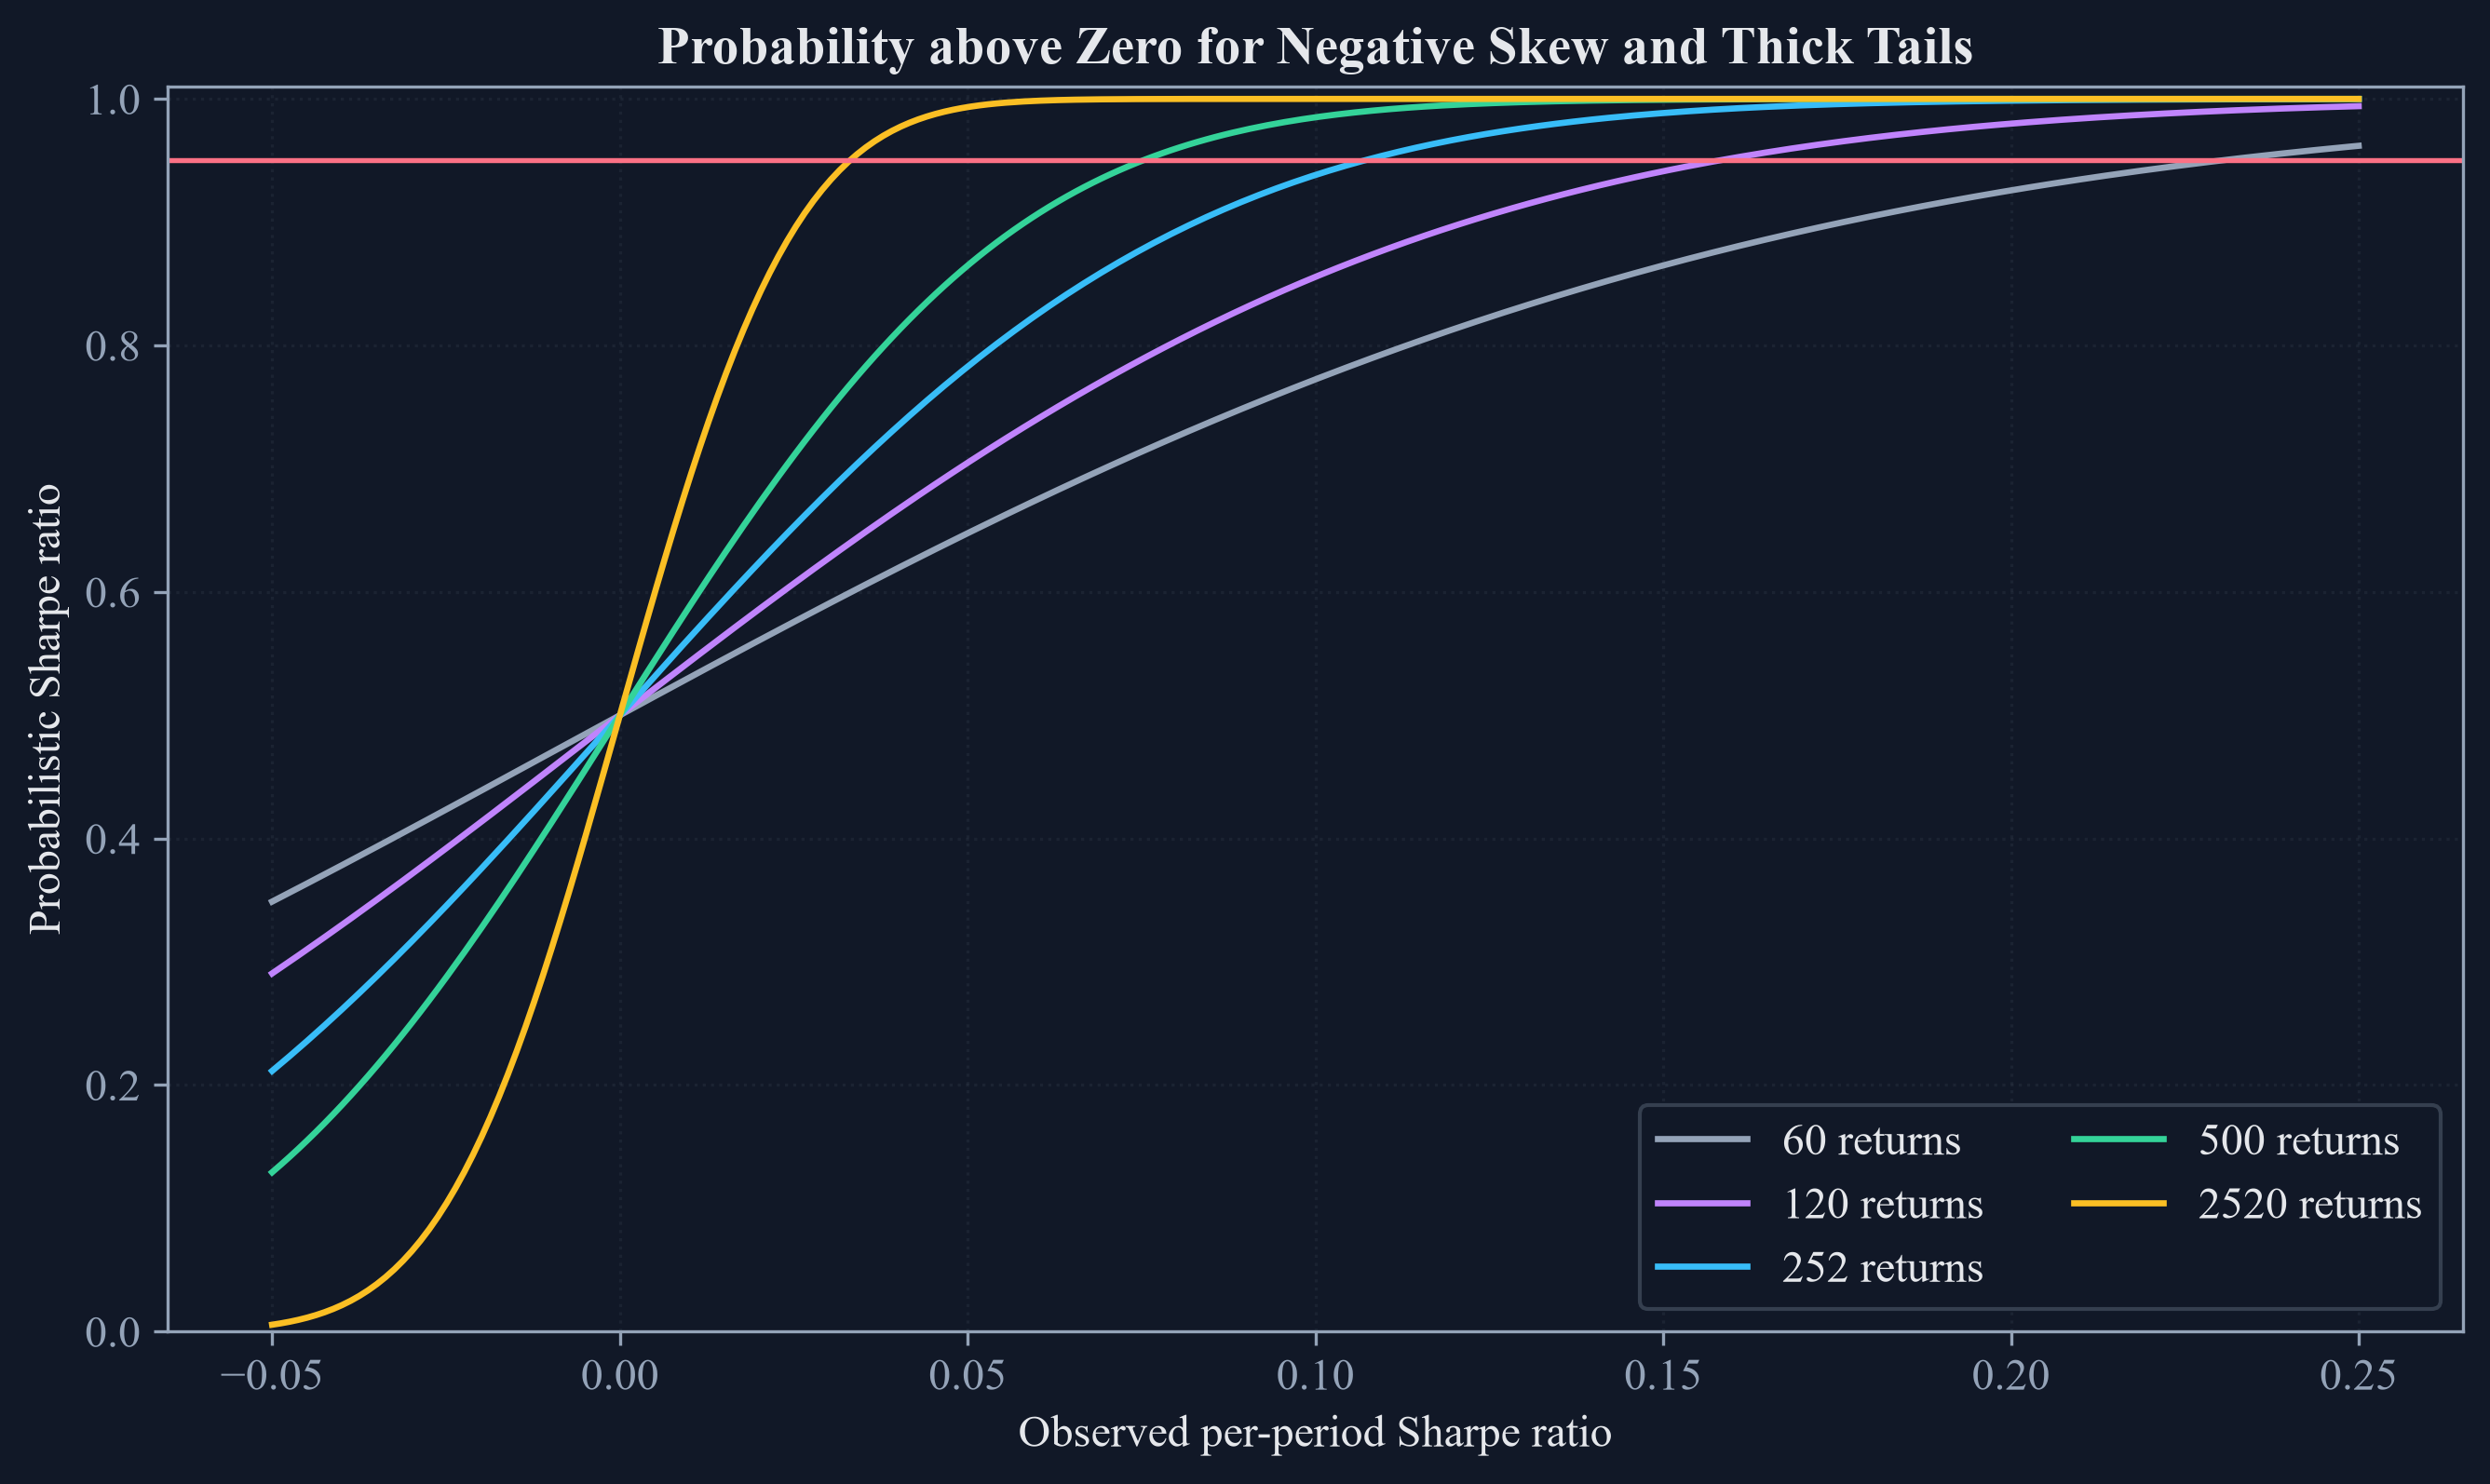

In [4]:
sample_sizes = [60, 120, 252, 500, 2520]
observed_values = [0.02, 0.05, 0.10, 0.15, 0.20]
psr_rows = []
for sample_size in sample_sizes:
    for observed in observed_values:
        psr_rows.append({"Returns": sample_size, "Observed Sharpe": observed, "Normal returns": probabilistic_sharpe_ratio(observed, 0.0, sample_size, 0.0, 3.0), "Negative skew and thick tails": probabilistic_sharpe_ratio(observed, 0.0, sample_size, -0.5, 4.0)})
psr_sensitivity = pd.DataFrame(psr_rows)
claimed_annual = 1.98
n_returns = 2520
preliminary_psr_reproduction = pd.DataFrame({
    "Calculation": ["Preliminary numerical input", "Daily value consistent with annual Sharpe"],
    "Sharpe used in formula": [claimed_annual, claimed_annual / np.sqrt(252.0)],
    "Returns": [n_returns, n_returns],
    "Skewness": [-0.5, -0.5],
    "Kurtosis": [4.0, 4.0],
    "PSR against zero": [probabilistic_sharpe_ratio(claimed_annual, 0.0, n_returns, -0.5, 4.0), probabilistic_sharpe_ratio(claimed_annual / np.sqrt(252.0), 0.0, n_returns, -0.5, 4.0)],
})
save_table(psr_sensitivity, "psr_sensitivity", "Probabilistic Sharpe ratios across sample lengths and return shapes.", "tab:chapter18-psr-sensitivity", fit=False)
save_table(preliminary_psr_reproduction, "preliminary_psr_reproduction", "The preliminary PSR calculation and a frequency-consistent daily conversion.", "tab:chapter18-preliminary-psr")
display(psr_sensitivity)
display(preliminary_psr_reproduction)

sharpe_grid = np.linspace(-0.05, 0.25, 240)
figure, axis = plt.subplots(figsize=(8.8, 5.2), constrained_layout=True)
colors = [palette["muted"], palette["violet"], palette["cyan"], palette["green"], palette["amber"]]
for sample_size, color in zip(sample_sizes, colors):
    values = [probabilistic_sharpe_ratio(sharpe, 0.0, sample_size, -0.5, 4.0) for sharpe in sharpe_grid]
    axis.plot(sharpe_grid, values, color=color, linewidth=1.6, label=f"{sample_size} returns")
axis.axhline(0.95, color=palette["rose"], linewidth=1.3)
axis.set_ylim(0, 1.01)
axis.set_title("Probability above Zero for Negative Skew and Thick Tails")
axis.set_xlabel("Observed per-period Sharpe ratio")
axis.set_ylabel("Probabilistic Sharpe ratio")
axis.legend(ncol=2)
axis.grid(alpha=0.28)
figure.savefig(FIGURES / "psr_curves.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "psr_curves.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "psr_curves.png")))
plt.close(figure)

## Tests

In [5]:
assert prices.index.is_monotonic_increasing
assert not prices.index.has_duplicates
assert len(prices) == 2330
assert observation_count == 2090
assert trial_count == 32
assert strategy_catalog.shape == (32, 5)
assert public_sharpe_inference.shape == (32, 8)
assert leading_public_inference.shape == (10, 8)
assert public_sharpe_inference['PSR against zero'].between(0, 1).all()
assert public_sharpe_inference['Deflated probability'].between(0, 1).all()
assert np.isclose(benchmark_sharpe_ratio(trial_sharpes), expected_max_sharpe_ratio(trial_count, 0.0, trial_spread))
assert expected_maximum_sensitivity['Trials'].tolist() == trial_counts
assert expected_maximum_sensitivity['Benchmark when mean is zero'].is_monotonic_increasing
assert expected_maximum_simulation.shape == (4, 5)
assert np.all(np.abs(expected_maximum_simulation['Simulated mean maximum'] - expected_maximum_simulation['Analytical expected maximum']) <= 3.0 * expected_maximum_simulation['Simulated standard error'] + 0.015)
assert preliminary_maxima.shape == (1000,)
assert 1.2 < preliminary_maxima.mean() < 1.35
assert psr_sensitivity.shape == (25, 4)
assert preliminary_psr_reproduction.shape == (2, 6)
assert preliminary_psr_reproduction['PSR against zero'].between(0, 1).all()
assert np.isclose(estimated_sharpe_ratio_z_statistics(0.1, 120, 0.0, -0.5, 4), probabilistic_sharpe_ratio(0.1, 0.0, 120, -0.5, 4, return_test_statistic=True))
assert (FIGURES / 'public_deflated_sharpe.pdf').is_file()
assert (FIGURES / 'expected_maximum_curve.pdf').is_file()
assert (FIGURES / 'psr_curves.pdf').is_file()
assert (TABLES / 'data_provenance.tex').is_file()
assert (TABLES / 'public_sharpe_inference.tex').is_file()
assert (TABLES / 'leading_public_inference.tex').is_file()
assert (TABLES / 'expected_maximum_sensitivity.tex').is_file()
assert (TABLES / 'expected_maximum_simulation.tex').is_file()
assert (TABLES / 'preliminary_expected_max_reproduction.tex').is_file()
assert (TABLES / 'psr_sensitivity.tex').is_file()
assert (TABLES / 'preliminary_psr_reproduction.tex').is_file()
